<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Data Visualization: Box Plots | Portfolio Edition**
**IBM Skills Network guided lab**

### Project Overview
Compensation and professional experience can vary considerably across developers. Looking only at averages can hide these differences, especially when a few unusually high values affect the results. In this notebook, I use box plots to examine how survey responses are distributed and compare them across age groups, developer roles, countries, employment categories, and job satisfaction scores.

**Guiding question:** How do compensation and professional experience vary across groups of developer survey respondents?

**Approach:** Connect to the survey database, retrieve relevant fields using SQL, prepare the data, create box plots, and assess what the visualizations can and cannot tell us.

**Tools and skills:** SQLite, SQL, Python, Pandas, Matplotlib, distribution analysis, outlier handling, and comparative visualization.

*This is an IBM Skills Network guided lab. The original workflow, code, saved outputs, and attribution are retained; the additional commentary is written for portfolio readers.*

Estimated time needed: **45** minutes


### Objectives


In this lab you will perform the following:
-   Visualize the distribution of data.
-   Visualize the relationship between two features.
-   Visualize data composition and comparisons using box plots.

#### Setup: Connecting to the Database


#### 1. Download the Database File


In [1]:
!wget https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/QR9YeprUYhOoLafzlLspAw/survey-results-public.sqlite

--2026-10-14 21:50:14--  https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/QR9YeprUYhOoLafzlLspAw/survey-results-public.sqlite
Resolving cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)... 169.63.118.104
Connecting to cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)|169.63.118.104|:443... connected.
HTTP request sent, awaiting response... 
200 OK
Length: 211415040 (202M) [application/octet-stream]
Saving to: ‘survey-results-public.sqlite’

          survey-re   0%[                    ]       0  --.-KB/s               
         survey-res   1%[                    ]   3.12M  15.6MB/s               
        survey-resu   4%[                    ]   9.52M  23.8MB/s               
       survey-resul   7%[>                   ]  15.83M  26.4MB/s               
      survey-result   8%[>                   ]  17.83M  22.3MB/s             

#### 2. Connect to the Database


**Install the needed libraries**


In [2]:
!pip install pandas

In [3]:
!pip install matplotlib
!pip install seaborn

In [5]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Connect to the SQLite database
conn = sqlite3.connect('survey-results-public.sqlite')

### Demo: Basic SQL Queries


#### Demo 1: Count the Number of Rows in the Table


In [7]:
QUERY = "SELECT COUNT(*) FROM main"
df = pd.read_sql_query(QUERY, conn)
print(df)

   COUNT(*)
0     65437

The saved query returns 65,437 rows in the main table. A grouped age count provides an initial view of the respondents, with the 25-34 category having the largest count in the displayed results (23,911).

These figures describe the available survey responses; they should not be treated as estimates for all developers.

#### Demo 2: List All Tables


In [9]:
QUERY = """
SELECT name as Table_Name 
FROM sqlite_master 
WHERE type = 'table'
"""
pd.read_sql_query(QUERY, conn)

,Table_Name
0,main


#### Demo 3: Group Data by Age


In [10]:
QUERY = """
SELECT Age, COUNT(*) as count 
FROM main 
GROUP BY Age 
ORDER BY Age
"""
df_age = pd.read_sql_query(QUERY, conn)
print(df_age)

                  Age  count
0     18-24 years old  14098
1     25-34 years old  23911
2     35-44 years old  14942
3     45-54 years old   6249
4     55-64 years old   2575
5   65 years or older    772
6   Prefer not to say    322
7  Under 18 years old   2568

### Visualizing Data


#### Task 1: Visualizing the Distribution of Data


**1. Box Plot of `CompTotal` (Total Compensation)**


Use a box plot to analyze the distribution and outliers in total compensation.<br> I retrieve non-missing CompTotal values and use the upper IQR threshold to filter unusually high observations before plotting. This makes the central distribution easier to see, but the chart no longer represents the complete range of reported compensation.


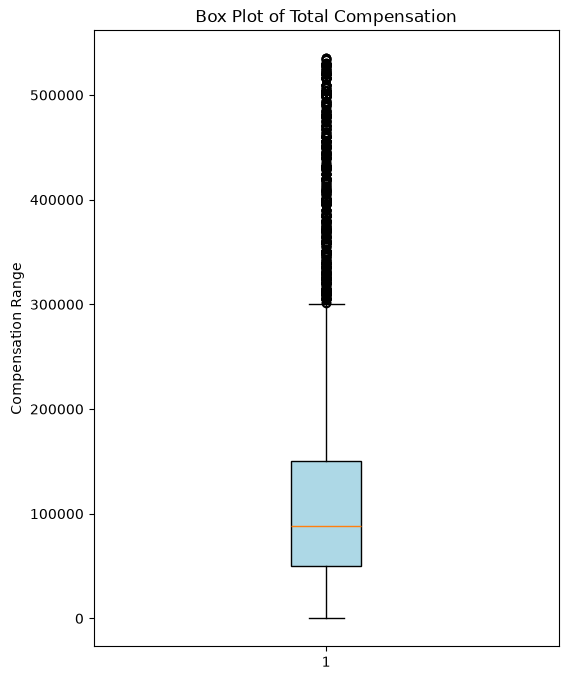

In [13]:
# your code goes here
QUERY = "SELECT CompTotal FROM main WHERE CompTotal IS NOT NULL"
df_comp = pd.read_sql_query(QUERY, conn)

Q1 = df_comp['CompTotal'].quantile(0.25)
Q3 = df_comp['CompTotal'].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR
df_comp_filtered = df_comp[df_comp['CompTotal'] <= upper_limit]

plt.figure(figsize=(6, 8))
plt.boxplot(df_comp_filtered['CompTotal'], patch_artist=True, boxprops=dict(facecolor='lightblue'))
plt.title('Box Plot of Total Compensation')
plt.ylabel('Compensation Range')
plt.show()

An important limitation is that `CompTotal` may reflect different local currencies. Without converting amounts to a consistent currency, the plot is best understood as a demonstration of distribution analysis, not a reliable comparison of salaries.

**2. Box Plot of Age (converted to numeric values)**


Convert the `Age` column into numerical values and visualize the distribution.


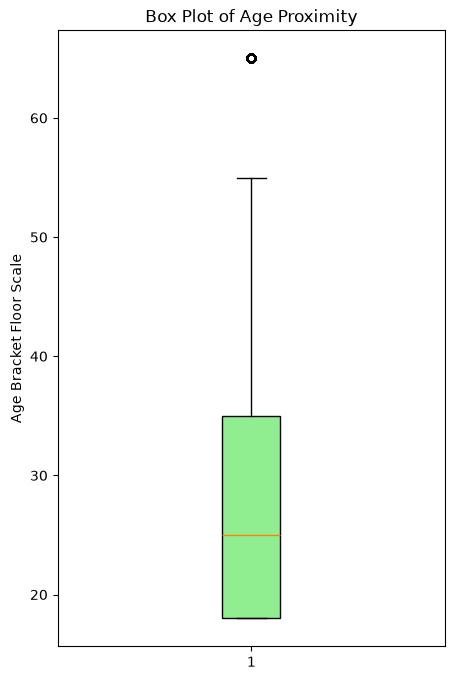

In [12]:
# your code goes here
QUERY = "SELECT Age FROM main WHERE Age IS NOT NULL"
df_age = pd.read_sql_query(QUERY, conn)

extracted_age = df_age['Age'].astype(str).str.extract(r'(\d+)').iloc[:, 0]
df_age['Age_clean'] = pd.to_numeric(extracted_age, errors='coerce')
df_age = df_age.dropna(subset=['Age_clean'])

plt.figure(figsize=(5, 8))
plt.boxplot(df_age['Age_clean'], patch_artist=True, boxprops=dict(facecolor='lightgreen'))
plt.title('Box Plot of Age Proximity')
plt.ylabel('Age Bracket Floor Scale')
plt.show()

### Task 2: Visualizing Relationships in Data


**1. Box Plot of `CompTotal` Grouped by Age Groups:**


Visualize the distribution of compensation across different age groups.<br> Unlike a single average, these plots show the median and spread for each group, helping reveal differences in variation as well as central values.

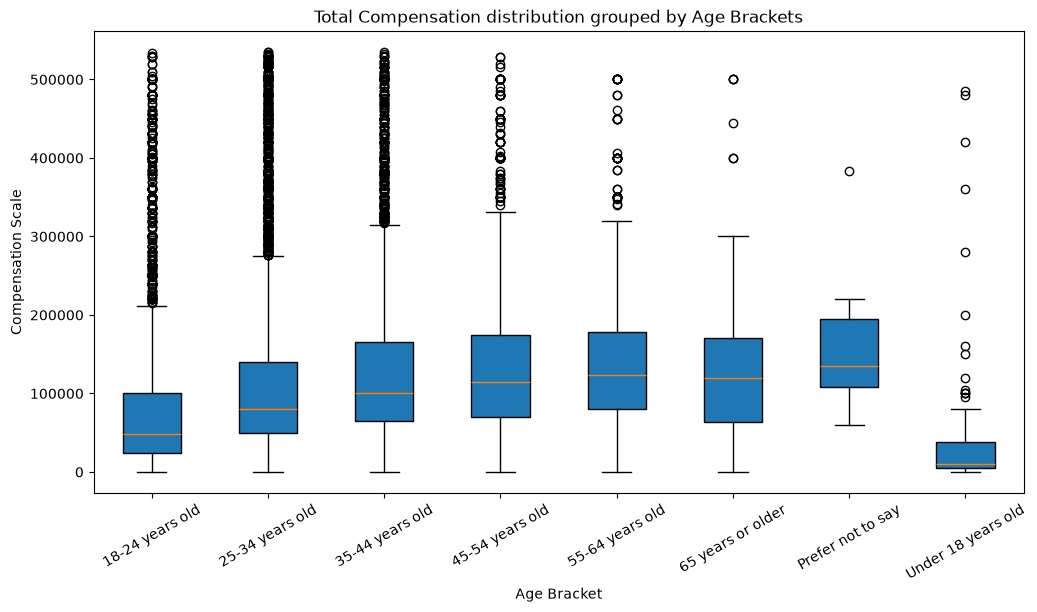

In [15]:
# your code goes here
QUERY = "SELECT Age, CompTotal FROM main WHERE Age IS NOT NULL AND CompTotal IS NOT NULL"
df_group_age = pd.read_sql_query(QUERY, conn)

Q1 = df_group_age['CompTotal'].quantile(0.25)
Q3 = df_group_age['CompTotal'].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR
df_group_age_filtered = df_group_age[df_group_age['CompTotal'] <= upper_limit]

age_order = sorted(df_group_age_filtered['Age'].unique())
data_to_plot = [df_group_age_filtered[df_group_age_filtered['Age'] == group]['CompTotal'] for group in age_order]

plt.figure(figsize=(12, 6))
plt.boxplot(data_to_plot, tick_labels=age_order, patch_artist=True)
plt.title('Total Compensation distribution grouped by Age Brackets')
plt.xlabel('Age Bracket')
plt.ylabel('Compensation Scale')
plt.xticks(rotation=30)
plt.show()

Each box represents a reported age category. Comparing their medians and spreads can highlight differences within this survey sample.

The code applies one upper outlier threshold across all selected respondents before dividing them into age groups. As a result, the displayed distributions exclude high values using a common cutoff, and group-specific extremes may be affected differently. `CompTotal` also has the currency-comparability limitation noted above.

**2. Box Plot of `CompTotal` Grouped by Job Satisfaction (`JobSatPoints_6`):**


Examine how compensation varies based on job satisfaction levels.


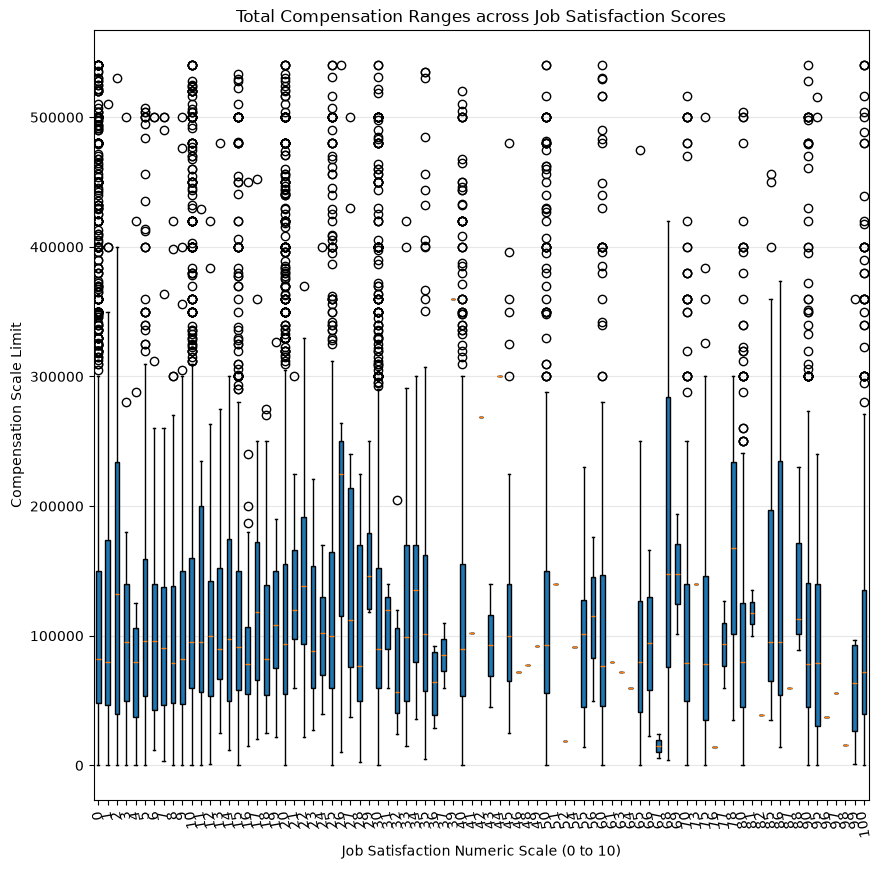

In [36]:
# your code goes here
QUERY = "SELECT JobSatPoints_6, CompTotal FROM main WHERE JobSatPoints_6 IS NOT NULL AND CompTotal IS NOT NULL"
df_jobsat = pd.read_sql_query(QUERY, conn)

df_jobsat['JobSatPoints_6'] = df_jobsat['JobSatPoints_6'].astype(int)

Q1 = df_jobsat['CompTotal'].quantile(0.25)
Q3 = df_jobsat['CompTotal'].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR
df_jobsat_filtered = df_jobsat[df_jobsat['CompTotal'] <= upper_limit]

sat_levels = sorted(df_jobsat_filtered['JobSatPoints_6'].unique())
data_to_plot = [df_jobsat_filtered[df_jobsat_filtered['JobSatPoints_6'] == lvl]['CompTotal'] for lvl in sat_levels]

plt.figure(figsize=(10, 10))
plt.boxplot(data_to_plot, tick_labels=sat_levels, patch_artist=True)
plt.title('Total Compensation Ranges across Job Satisfaction Scores')
plt.xlabel('Job Satisfaction Numeric Scale (0 to 10)')
plt.ylabel('Compensation Scale Limit')
plt.grid(axis='y', alpha=0.3) 
plt.xticks(rotation=100)
plt.show()

### Task 3: Visualizing the Composition of Data


**1. Box Plot of `ConvertedCompYearly` for the Top 5 Developer Types:**


Analyze compensation across the top 5 developer roles.<br> Respondents may select multiple roles, so one person can appear in more than one role group. The chart uses ConvertedCompYearly and filters high values using an IQR-based cutoff. It describes differences in the observed responses rather than definitive salary benchmarks for each role.


/tmp/ipykernel_1747/3402296830.py:19: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(data_to_plot, tick_labels=top_5, vert=False, patch_artist=True)

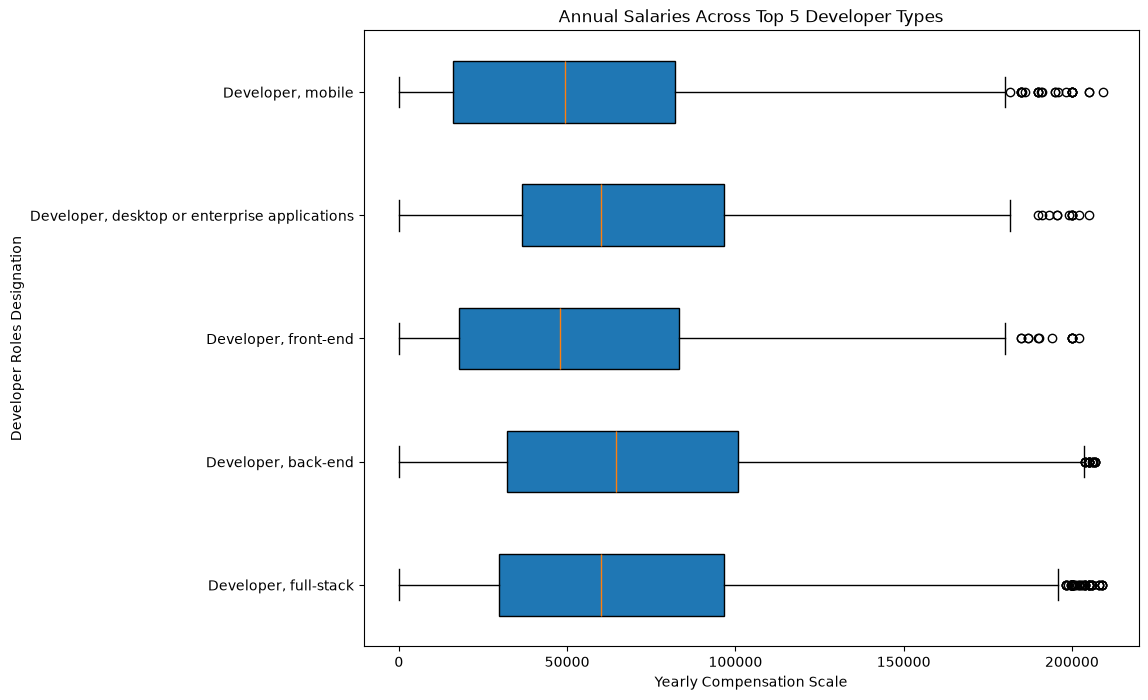

In [20]:
# your code goes here
QUERY = "SELECT DevType, ConvertedCompYearly FROM main WHERE DevType IS NOT NULL AND ConvertedCompYearly IS NOT NULL"
df_dev = pd.read_sql_query(QUERY, conn)
df_exploded_dev = df_dev.assign(DevType=df_dev['DevType'].str.split(';')).explode('DevType')

top_5 = df_exploded_dev['DevType'].value_counts().head(5).index
df_top_dev = df_exploded_dev[df_exploded_dev['DevType'].isin(top_5)]

Q1 = df_top_dev['ConvertedCompYearly'].quantile(0.25)
Q3 = df_top_dev['ConvertedCompYearly'].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR
df_top_dev_filtered = df_top_dev[df_top_dev['ConvertedCompYearly'] <= upper_limit]


data_to_plot = [df_top_dev_filtered[df_top_dev_filtered['DevType'] == role]['ConvertedCompYearly'] for role in top_5]

plt.figure(figsize=(10, 8))
plt.boxplot(data_to_plot, tick_labels=top_5, vert=False, patch_artist=True)
plt.title('Annual Salaries Across Top 5 Developer Types')
plt.xlabel('Yearly Compensation Scale')
plt.ylabel('Developer Roles Designation')
plt.show()

**2. Box Plot of `CompTotal` for the Top 5 Countries:**


Analyze compensation across respondents from the top 5 countries.<br> This chart compares CompTotal among the five countries with the most non-missing compensation responses in this query.


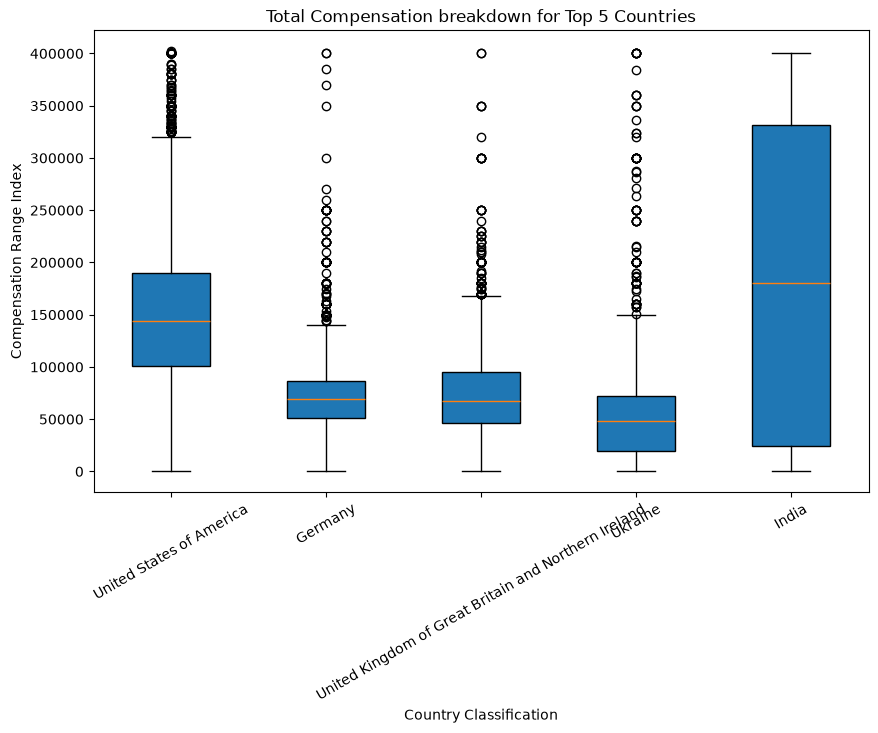

In [24]:
# your code goes here
QUERY = "SELECT Country, CompTotal FROM main WHERE Country IS NOT NULL AND CompTotal IS NOT NULL"
df_country = pd.read_sql_query(QUERY, conn)

top_5_countries = df_country['Country'].value_counts().head(5).index
df_top = df_country[df_country['Country'].isin(top_5_countries)]

Q1 = df_top['CompTotal'].quantile(0.25)
Q3 = df_top['CompTotal'].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR
df_top_filtered = df_top[df_top['CompTotal'] <= upper_limit]

data_to_plot = [df_top_filtered[df_top_filtered['Country'] == nation]['CompTotal'] for nation in top_5_countries]

plt.figure(figsize=(10, 6))
plt.boxplot(data_to_plot, tick_labels=top_5_countries, patch_artist=True)
plt.title('Total Compensation breakdown for Top 5 Countries')
plt.xlabel('Country Classification')
plt.ylabel('Compensation Range Index')
plt.xticks(rotation=30)
plt.show()

### Task 4: Visualizing Comparison of Data


**1. Box Plot of CompTotal Across Employment Types:**


Analyze compensation for different employment types.<br> The final two charts look at compensation across employment categories and professional coding experience across job satisfaction scores. Together, they show how box plots can support comparisons beyond a single numeric variable.


/tmp/ipykernel_1747/3253402341.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(data_to_plot, tick_labels=emp_types, vert=False, patch_artist=True)

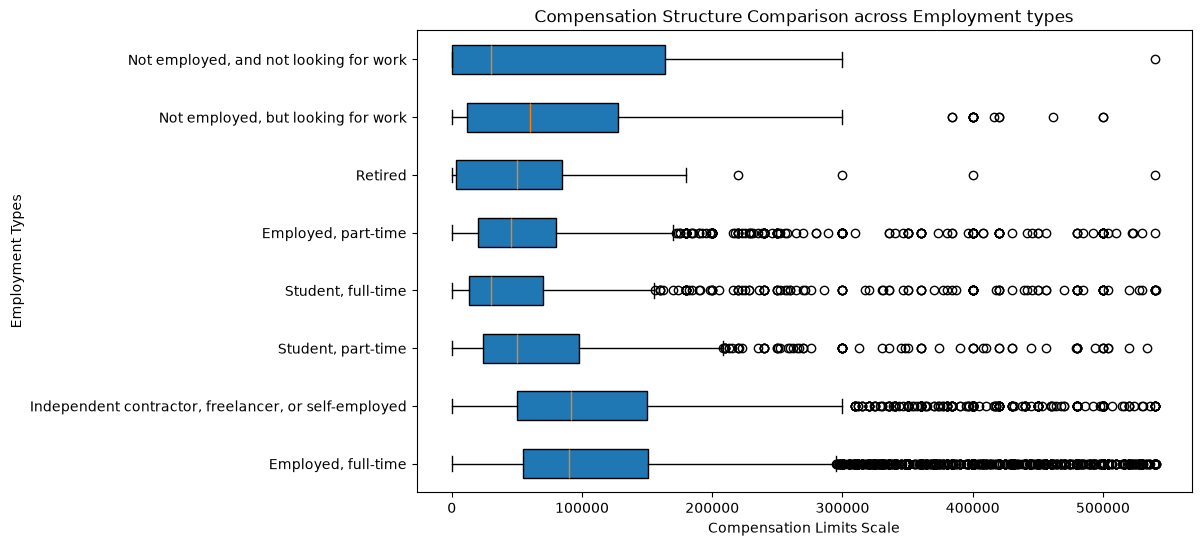

In [26]:
# your code goes here
QUERY = "SELECT Employment, CompTotal FROM main WHERE Employment IS NOT NULL AND CompTotal IS NOT NULL"
df_emp = pd.read_sql_query(QUERY, conn)

df_exploded_emp = df_emp.assign(Employment=df_emp['Employment'].str.split(';')).explode('Employment')
Q1 = df_exploded_emp['CompTotal'].quantile(0.25)
Q3 = df_exploded_emp['CompTotal'].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR
df_exploded_emp_filtered = df_exploded_emp[df_exploded_emp['CompTotal'] <= upper_limit]

emp_types = df_exploded_emp_filtered['Employment'].unique()
data_to_plot = [df_exploded_emp_filtered[df_exploded_emp_filtered['Employment'] == emp]['CompTotal'] for emp in emp_types]

plt.figure(figsize=(10, 6))
plt.boxplot(data_to_plot, tick_labels=emp_types, vert=False, patch_artist=True)
plt.title('Compensation Structure Comparison across Employment types')
plt.xlabel('Compensation Limits Scale')
plt.ylabel('Employment Types')
plt.show()

**2. Box Plot of `YearsCodePro` by Job Satisfaction (`JobSatPoints_6`):**


Examine the distribution of professional coding years by job satisfaction levels.


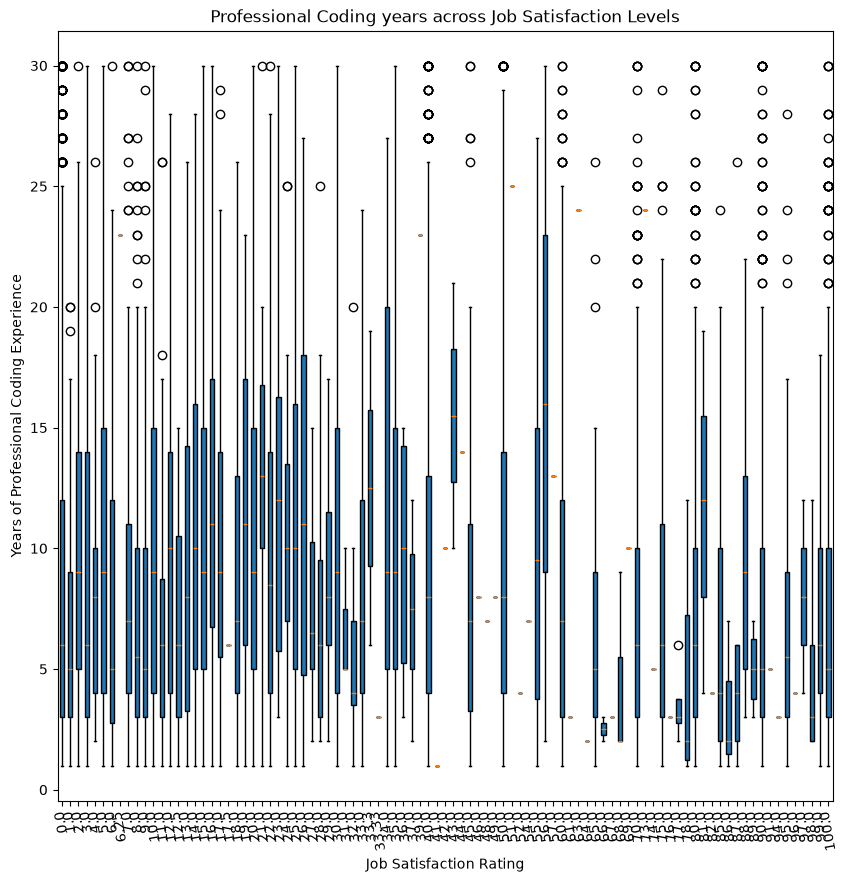

In [39]:
# your code goes here
QUERY = "SELECT JobSatPoints_6, YearsCodePro FROM main WHERE JobSatPoints_6 IS NOT NULL AND YearsCodePro IS NOT NULL"
df_years_sat = pd.read_sql_query(QUERY, conn)

extracted_years = df_years_sat['YearsCodePro'].astype(str).str.extract(r'(\d+)').iloc[:, 0]
df_years_sat['YearsCodePro_clean'] = pd.to_numeric(extracted_years, errors='coerce')
df_years_sat = df_years_sat.dropna(subset=['YearsCodePro_clean'])

Q1 = df_years_sat['YearsCodePro_clean'].quantile(0.25)
Q3 = df_years_sat['YearsCodePro_clean'].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR
lower_limit = Q1 - 1.5 * IQR
df_years_sat_filtered = df_years_sat[(df_years_sat['YearsCodePro_clean'] >= lower_limit) & (df_years_sat['YearsCodePro_clean'] <= upper_limit)]

sat_levels = sorted(df_years_sat_filtered['JobSatPoints_6'].unique())
data_to_plot = [df_years_sat_filtered[df_years_sat_filtered['JobSatPoints_6'] == lvl]['YearsCodePro_clean'] for lvl in sat_levels]

plt.figure(figsize=(10, 10))
plt.boxplot(data_to_plot, tick_labels=sat_levels, patch_artist=True)
plt.title('Professional Coding years across Job Satisfaction Levels')
plt.xlabel('Job Satisfaction Rating')
plt.ylabel('Years of Professional Coding Experience')
plt.xticks(rotation=100)
plt.show()

#### Final Step: Close the Database Connection


After completing the lab, close the connection to the SQLite database:


In [40]:
conn.close()

### Key Findings
- The database contains 65,437 survey records, providing several groups for exploratory comparisons.
- Box plots make it easier to examine the median, spread, and unusually high or low values rather than relying only on averages.
- The notebook demonstrates comparisons across age, satisfaction, developer roles, countries, and employment types. These charts support exploration but do not, on their own, establish causes.
- Interpretation depends on how values were prepared. In particular, outlier filtering, multi-select survey responses, and different compensation fields affect what can be concluded.

### Limitations and Next Steps
This is an exploratory, guided analysis of survey responses. The results may not represent the broader developer population. Several charts use CompTotal, which may combine amounts reported in different currencies; age and experience fields also contain ranges or text rather than exact numeric measurements.

For a more rigorous follow-up, I would standardize compensation units, review the proportion of observations excluded by outlier filters, retain the original category labels where appropriate, and compare group sizes alongside their box plots. I would also avoid interpreting differences as causal effects without additional analysis.

### Skills Demonstrated
- SQL and data access: Connecting to SQLite and querying selected survey fields.
- Data preparation: Handling missing entries, multi-select responses, numeric conversion, and IQR-based filtering.
- Visualization: Creating and interpreting single-group and grouped box plots in Matplotlib.
- Analytical communication: Explaining variation, assumptions, and limitations in a format suitable for non-technical readers.

### Summary


In this lab, you used box plots to visualize various aspects of the dataset, focusing on:

- Visualize distributions of compensation and age.
- Explore relationships between compensation, job satisfaction, and professional coding experience.
- Analyze data composition across developer roles and countries.
- Compare compensation across employment types and satisfaction levels.

*The original notebook and saved outputs are from an IBM Skills Network guided lab. Explanatory portfolio commentary has been added.*

### Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


<!--## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|               
|2024-10-07|1.2|Madhusudan Moole|Reviewed and updated lab|                                                                                      
|2024-10-06|1.0|Raghul Ramesh|Created lab|-->


Copyright © IBM Corporation. All rights reserved.
